# Dataset Type

In [ ]:
DATASET_TYPE = "downloaded" # Options are "internal" or "downloaded"

# Load Data

In [ ]:
# Import scikit-learn dataset library
from sklearn import datasets

def get_label_mapping(i):
  # Map between labels to help in visualizing them later
  if i == 1:
    return labels[0]
  else:
    return "Not " + labels[0]

def get_label_list_mapping(labels):
  return list(set([get_label_mapping(i) for i, label in enumerate(labels)]))

if DATASET_TYPE == "internal":
  MODE = "differentiable"    # Options: differentiable or non-differentiable

  if MODE == "differentiable":
    # Load differentiable dataset
    svm_data = datasets.load_iris()
  else:
    # Load non-differentiable dataset
    svm_data = datasets.load_breast_cancer()

  idx1, idx2 = 2, 3
  X_plot = svm_data.data

  X = [[x[idx1], x[idx2]] for x in svm_data.data]
  y = svm_data.target.copy()

  feature_names = svm_data.feature_names
  labels = svm_data.target_names
  cm_labels = get_label_list_mapping(labels)


# OR: Download Dataset from file

In [ ]:
import numpy as np
import pandas as pd

if DATASET_TYPE == "downloaded":
  MODE = "non-differentiable"

  svm_data = pd.read_csv('http://nrvis.com/data/mldata/breast-cancer-wisconsin_wdbc.csv')

  idx1, idx2 = 2, 3
  X_plot = svm_data.iloc[:, 2:].to_numpy()

  X = [[x[idx1], x[idx2]] for x in svm_data.iloc[:, 2:].to_numpy()]
  y = svm_data.iloc[:, 1].to_numpy()
  feature_names = svm_data.columns
  labels = ["malignant", "benign"]  #feature_names[1]
  cm_labels = ["malignant", "benign"]

  # Map labels from ['M', 'B'] to [0, 1] space
  y = np.where(y=='M', 0, 1)

# Explore the Data

In [ ]:
# print the names of the features
print("Features: ", feature_names)

# print the label type of targets
print("Labels: ", labels)

Features:  Index(['%id', 'diagnosis (M=malignant; B=benign)', 'radius (nucA)',
       'texture (nucA)', 'perimeter (nucA)', 'area (nucA)',
       'smoothness (nucA)', 'compactness (nucA)', 'concavity (nucA)',
       'concave points (nucA)', 'symmetry (nucA)', 'fractal dimension (nucA)',
       'radius (nucB)', 'texture (nucB)', 'perimeter (nucB)', 'area (nucB)',
       'smoothness (nucB)', 'compactness (nucB)', 'concavity (nucB)',
       'concave points (nucB)', 'symmetry (nucB)', 'fractal dimension (nucB)',
       'radius (nucC)', 'texture (nucC)', 'perimeter (nucC)', 'area (nucC)',
       'smoothness (nucC)', 'compactness (nucC)', 'concavity (nucC)',
       'concave points (nucC)', 'symmetry (nucC)', 'fractal dimension (nucC)'],
      dtype='object')
Labels:  ['malignant', 'benign']


# Scale the data

In [ ]:
# Image processing and pixel values - min-max scaling
# knn-clustering or regression which use distance metrics - standardization
# SVM or logistic regression or Neural Network which use gradiant descent - standardization
# decision tree and random forest - not distance based, hence no scaling is needed

# Normalize the data - Convert to range [0, 1]
# X = (X - np.min(X, axis=0)) / (np.max(X, axis=0) - np.min(X, axis=0))
# X_plot = (X_plot - np.min(X_plot, axis=0)) / (np.max(X_plot, axis=0) - np.min(X_plot, axis=0))
# Standardize the data - Convert to a normal distribution with mean 0 and standard deviation of 1
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
X_plot = (X_plot - np.mean(X_plot, axis=0)) / np.std(X_plot, axis=0)

# Remap labels

In [ ]:
for i in range(len(y)):
    if y[i] == 0: y[i] = 1
    else: y[i] = -1

# Visualize the data

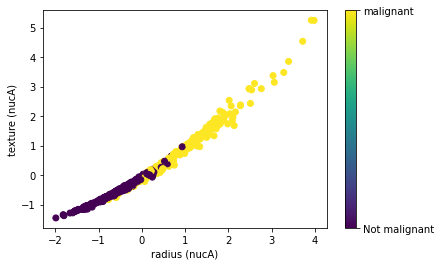

In [ ]:
from matplotlib import pyplot as plt

def plot(x_index, y_index):
    formatter = plt.FuncFormatter(lambda i, *args: get_label_mapping(int(i)))
    plt.scatter(X_plot[:, x_index], X_plot[:, y_index], c=y)
    plt.colorbar(ticks=[1, -1], format=formatter)
    plt.xlabel(feature_names[x_index])
    plt.ylabel(feature_names[y_index])

plt.figure(figsize=(14, 4))
plt.subplot(121)
plot(idx1, idx2)

# Split the Data into Train and Test Sets

In [ ]:
# Import train_test_split function
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Visualize the Train and Test Data Split

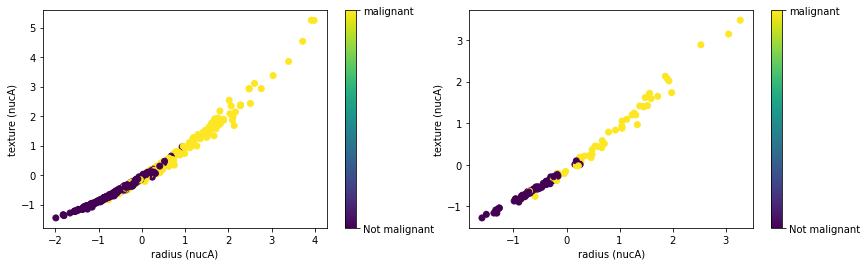

In [ ]:
import numpy as np

def plot(X_data, Y_data, x_index, y_index):

    formatter = plt.FuncFormatter(lambda i, *args: get_label_mapping(int(i)))
    plt.scatter(np.array(X_data)[:, 0], np.array(X_data)[:, 1], c=Y_data)
    plt.colorbar(ticks=[1, -1], format=formatter)
    plt.xlabel(feature_names[x_index])
    plt.ylabel(feature_names[y_index])

plt.figure(figsize=(14, 4))
plt.subplot(121)
plot(X_train, y_train, idx1, idx2)

plt.subplot(122)
plot(X_test, y_test, idx1, idx2)

plt.show()

# Train the Model

In [ ]:
#Import svm model
from sklearn import svm

#Create a svm Classifier
# Hyperparameters can be changed/tuned based on the compile and fit function arguments defined at -
# https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html
clf = svm.SVC(kernel='linear', C= 10) # Linear Kernel

#Train the model using the training sets
clf.fit(X_train, y_train)

SVC(C=10, break_ties=False, cache_size=200, class_weight=None, coef0=0.0,
    decision_function_shape='ovr', degree=3, gamma='scale', kernel='linear',
    max_iter=-1, probability=False, random_state=None, shrinking=True,
    tol=0.001, verbose=False)

# Predict the Model on Test data

In [ ]:
#Predict the response for test dataset
y_pred = clf.predict(X_test)

# Evaluate the Model on Test Data

In [ ]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics

# Model Accuracy: how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# Model Precision: what percentage of positive tuples are labeled as such?
print("Precision:",metrics.precision_score(y_test, y_pred))

# Model Recall: what percentage of positive tuples are labelled as such?
print("Recall:",metrics.recall_score(y_test, y_pred))

Accuracy: 0.8771929824561403
Precision: 0.9090909090909091
Recall: 0.8


# Visualize the Solution

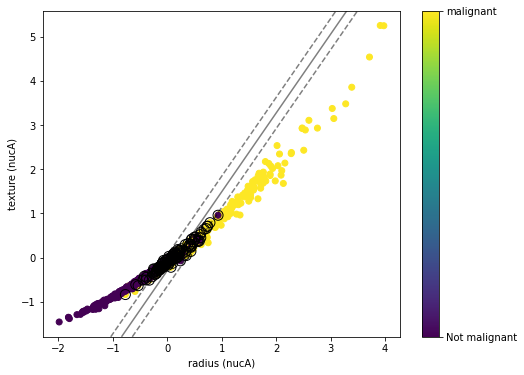

In [ ]:
import numpy as np

x_index = idx1
y_index = idx2

plt.figure(figsize=(8, 6))
formatter = plt.FuncFormatter(lambda i, *args: get_label_mapping(int(i)))
plt.scatter(X_plot[:, x_index], X_plot[:, y_index], c=y)
plt.colorbar(ticks=[1, -1], format=formatter)
plt.xlabel(feature_names[x_index])
plt.ylabel(feature_names[y_index])

ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

# create grid to evaluate model
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
Z = clf.decision_function(xy).reshape(XX.shape)

# plot decision boundary and margins
ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.5,
           linestyles=['--', '-', '--'])
# plot support vectors
ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=100,
           linewidth=1, facecolors='none', edgecolors='k')
plt.show()

# Plot Confusion Matrix

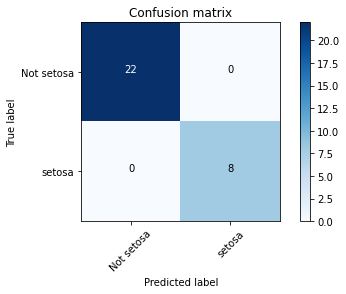

In [ ]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(cm, classes, normalize=False, title='Confusion matrix', cmap=plt.cm.Blues):
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt), horizontalalignment="center", color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

cm = confusion_matrix(y_test, y_pred)

plot_confusion_matrix(cm, cm_labels)  
plt.show()